# 3. Training the win model, step by step

The fight predictor is an L2-regularised logistic regression on the differences between two
fighters. `src/ufc_embedded/train.py` trains it in one go; this notebook does the same steps one
at a time, with scikit-learn and the project's own helpers, so each one can be looked at:

1. Data: one row per fight, features as differences A − B
2. The model
3. A first fit
4. Choosing the regularisation on rolling yearly validation
5. Evaluation: accuracy, log loss, calibration, the betting market
6. The final model and what drives a prediction

Reusable code lives in `src/ufc_embedded/`; this notebook only runs and explains it.

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import log_loss, roc_auc_score

from ufc_embedded.evaluate import CV_YEARS, TEST_START, calibration_table, metrics, rolling_folds
from ufc_embedded.train import FEATURE_LABELS, build, logistic, lr_inputs

%matplotlib inline
pd.set_option("display.width", 200)
plt.rcParams["figure.dpi"] = 110

## 1. Data

`build()` turns every UFC fight since 1994 into one row. Two traps in the raw data are handled
there:

- **No leakage.** UFCStats' career stats are as of *today*, so every feature is rebuilt from the
  fighter's *earlier* fights only.
- **Corners swapped at random.** The raw data always lists the winner first; without the swap a
  model would just learn the column order.

Each feature enters as the difference $d = x_A - x_B$; the label is $y = 1$ if A won.

In [2]:
data = build()
m = data.m
x = lr_inputs("v2")  # the 46 deployed features, as A - B differences
print(f"{len(m):,} fights, {len(x)} features, {m['date'].min():%Y} to {m['date'].max():%Y}")
print(f"A won {m['y'].mean():.1%} of fights: without features it's a coin flip")
m[["date", "a_name", "b_name", "y", "d_age", "d_reach", "d_pro_win_rate", "d_glicko"]].tail()

/Users/anar/Desktop/tum/26-winter/ufc_embedded/src/ufc_embedded/features.py:313: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  m[f"a_{col}"] = a[col].astype(float)
/Users/anar/Desktop/tum/26-winter/ufc_embedded/src/ufc_embedded/features.py:314: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  m[f"b_{col}"] = b[col].astype(float)
/Users/anar/Desktop/tum/26-winter/ufc_embedded/src/ufc_embedded/features.py:315: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which h

8,819 fights, 46 features, 1994 to 2026
A won 49.9% of fights: without features it's a coin flip


,date,a_name,b_name,y,d_age,d_reach,d_pro_win_rate,d_glicko
8814,2026-10-31,Cody Durden,Ode Osbourne,1.0,0.783025,-15.24,0.029570,0.083476
8815,2026-10-31,Francis Marshall,Dakota Hope,0.0,-2.088980,10.16,-0.066667,0.331779
8816,2026-10-31,Luana Santos,Yana Santos,1.0,-10.428474,-2.54,0.133333,0.197886
8817,2026-10-31,Jacobe Smith,Randy Brown,1.0,-5.527721,-15.24,0.233333,-0.012704
8818,2026-10-31,Nick Klein,Joe Kropschot,0.0,-0.221766,-5.08,-0.077922,-0.337717


Everything from 2024 on is the **locked test set** and isn't used in this notebook.

In [3]:
m = m[m["date"] < TEST_START]
print(f"{len(m):,} fights before {TEST_START:%Y}")

7,317 fights before 2024


## 2. The model

$$P(A \text{ beats } B) = \sigma\big(w^\top d\big), \qquad \sigma(z) = \frac{1}{1 + e^{-z}}$$

with no intercept. Swapping the corners turns $d$ into $-d$, and $\sigma(-z) = 1 - \sigma(z)$, so
$P(B \text{ beats } A) = 1 - P(A \text{ beats } B)$ exactly, whoever is called A. The weights
minimise the log loss plus an L2 penalty; scikit-learn writes it as

$$\min_w\; C \sum_{i=1}^{n} \Big[-y_i \log p_i - (1 - y_i)\log(1 - p_i)\Big] + \tfrac12 \lVert w \rVert^2,
\qquad p_i = \sigma(w^\top d_i)$$

so a **smaller $C$ means stronger regularisation**. `logistic(C)` is the exact pipeline the site
uses: scale each column by its standard deviation (without centring, which would break the
symmetry), then the logistic regression without intercept.

In [4]:
logistic(0.01)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('standardscaler', ...), ('logisticregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"with_mean with_mean: bool, default=TrueIf True, center the data before scaling.This does not work (and will raise an exception) when attempted onsparse matrices, because centering them entails building a densematrix which in common use cases is likely to be too large to fit inmemory.",False
,"copy copy: bool, default=TrueIf False, try to avoid a copy and do inplace scaling instead.This is not guaranteed to always work inplace; e.g. if the data isnot a NumPy array or scipy.sparse CSR matrix, a copy may still bereturned.",True
,"with_std with_std: bool, default=TrueIf True, scale the data to unit variance (or equivalently,unit standard deviation).",True
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",0.01
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",False
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",2000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'


## 3. A first fit

Train on fights before 2022, test on 2022–23.

In [5]:
train = m[m["date"].dt.year < 2022]
val = m[m["date"].dt.year.isin([2022, 2023])]
model = logistic(C=0.01).fit(train[x], train["y"])
p_train = model.predict_proba(train[x])[:, 1]
p_val = model.predict_proba(val[x])[:, 1]
pd.DataFrame(
    {
        "train (to 2021)": metrics(train["y"], p_train),
        "validation (2022-23)": metrics(val["y"], p_val),
    }
).T[["accuracy", "log_loss", "brier", "n"]].round(3)

,accuracy,log_loss,brier,n
train (to 2021),0.642,0.631,0.221,6307.0
validation (2022-23),0.629,0.649,0.229,1010.0


Log loss is the main metric: it rewards being confident only when it's deserved. A coin flip
scores $\ln 2 \approx 0.693$.

## 4. Choosing the regularisation

One validation period is noisy, so the pipeline uses **rolling validation**: predict each year
2019–23 with a model trained on all earlier years, and average. That's 5 fits per value of $C$.

In [6]:
folds = rolling_folds(m)  # [(train, test), ...] for 2019 ... 2023
for (tr, te), year in zip(folds, CV_YEARS, strict=True):
    print(f"{year}: train on {len(tr):,} earlier fights, predict {len(te):,}")

2019: train on 4,860 earlier fights, predict 506
2020: train on 5,366 earlier fights, predict 444
2021: train on 5,810 earlier fights, predict 497
2022: train on 6,307 earlier fights, predict 506
2023: train on 6,813 earlier fights, predict 504


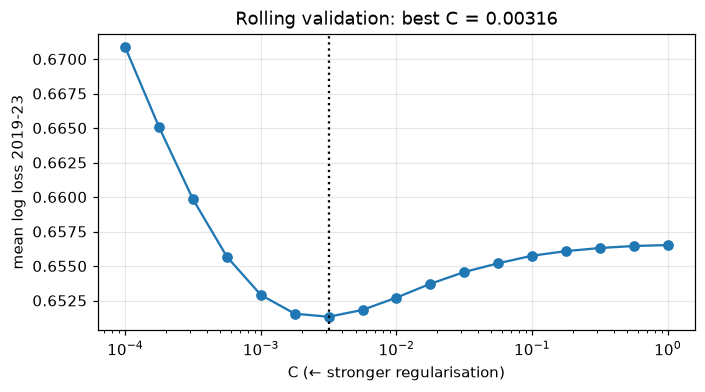

In [7]:
Cs = np.logspace(-4, 0, 17)
rows = []
for C in Cs:
    per_year = [
        log_loss(te["y"], logistic(C).fit(tr[x], tr["y"]).predict_proba(te[x])[:, 1])
        for tr, te in folds
    ]
    rows.append({"C": C, "rolling log loss": np.mean(per_year)})
sweep = pd.DataFrame(rows)
best_C = sweep.loc[sweep["rolling log loss"].idxmin(), "C"]

fig, ax = plt.subplots(figsize=(7, 3.5))
ax.semilogx(sweep["C"], sweep["rolling log loss"], marker="o")
ax.axvline(best_C, ls=":", color="k")
ax.set(
    xlabel="C (← stronger regularisation)",
    ylabel="mean log loss 2019-23",
    title=f"Rolling validation: best C = {best_C:.3g}",
)
ax.grid(alpha=0.3)
plt.show()

Too small a $C$ and the weights are squeezed toward 0 (everything near 50%); too large and
they chase noise in the training years.

## 5. Evaluation

Out-of-fold predictions for every fight of 2019–23, each from a model that never saw that year,
with the chosen $C$:

In [8]:
oof = pd.concat(
    [
        te.assign(p=logistic(best_C).fit(tr[x], tr["y"]).predict_proba(te[x])[:, 1])
        for tr, te in folds
    ]
)
odds = oof[oof["p_market"].notna()]


def scores(y, p):
    s = metrics(y, p)
    return {
        "accuracy": s["accuracy"],
        "log loss": s["log_loss"],
        "AUC": roc_auc_score(y, p),
        "fights": len(y),
    }


pd.DataFrame(
    {
        "our model": scores(oof["y"], oof["p"]),
        "our model, fights with odds": scores(odds["y"], odds["p"]),
        "betting market, same fights": scores(odds["y"], odds["p_market"]),
    }
).T.round(3)

,accuracy,log loss,AUC,fights
our model,0.621,0.652,0.660,2457.0
"our model, fights with odds",0.628,0.648,0.669,2284.0
"betting market, same fights",0.662,0.614,0.722,2284.0


**Calibration.** When the model says 70%, does that fighter win about 70% of the time?

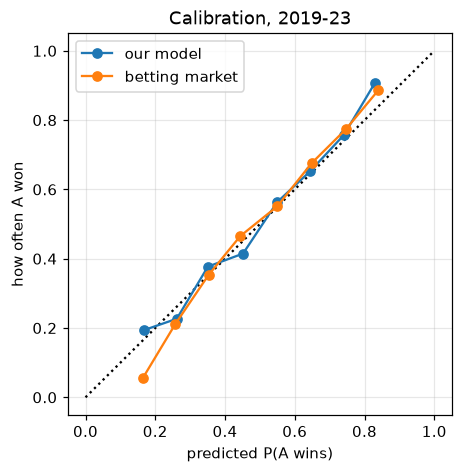

In [9]:
fig, ax = plt.subplots(figsize=(4.5, 4.5))
ax.plot([0, 1], [0, 1], ls=":", color="k")
for col, name in [("p", "our model"), ("p_market", "betting market")]:
    cal = calibration_table(odds["y"], odds[col])
    cal = cal[cal["n"] >= 20]
    ax.plot(cal["predicted"], cal["observed"], marker="o", label=name)
ax.set(xlabel="predicted P(A wins)", ylabel="how often A won", title="Calibration, 2019-23")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

**Confidence pays.** Accuracy when only the fights the model is surest about are counted:

In [10]:
conf = np.abs(oof["p"] - 0.5) + 0.5
right = (oof["p"] > 0.5) == (oof["y"] == 1)
pd.DataFrame(
    [
        {
            "model at least": f"{t:.0%} sure",
            "share of fights": (conf >= t).mean(),
            "accuracy": right[conf >= t].mean(),
        }
        for t in (0.5, 0.6, 0.7, 0.8)
    ]
).round(3)

,model at least,share of fights,accuracy
0,50% sure,1.000,0.621
1,60% sure,0.494,0.677
2,70% sure,0.153,0.772
3,80% sure,0.028,0.868


The market stays ahead: bookmakers know about injuries, short-notice replacements, training
camps and debutants' earlier careers, which the statistics don't contain.

## 6. The final model

Like the site: all fights before 2024, the chosen $C$.

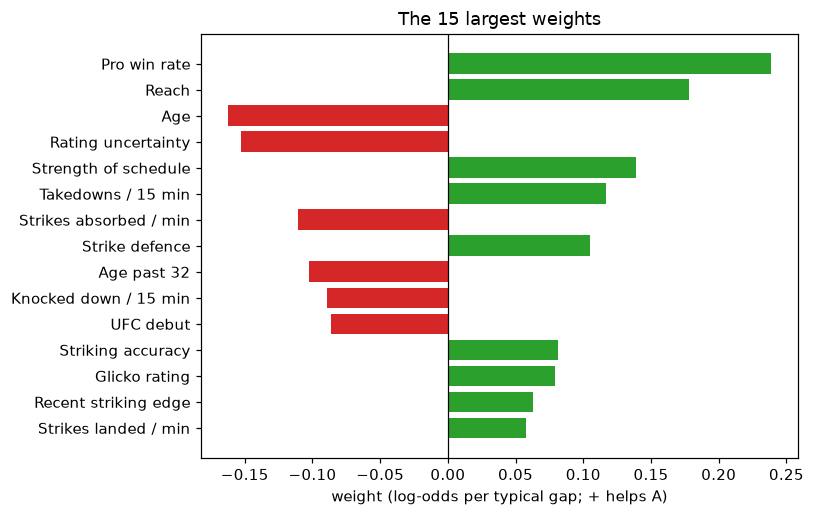

In [11]:
final = logistic(best_C).fit(m[x], m["y"])
scaler, lr = final.named_steps.values()
# Weights per standard deviation of each difference, so they're comparable.
names = [FEATURE_LABELS.get(c.removeprefix("d_"), c) for c in x]
weights = pd.Series(lr.coef_[0], index=names)
top = weights.sort_values(key=abs).tail(15)

fig, ax = plt.subplots(figsize=(7, 5))
ax.barh(top.index, top, color=["C2" if v > 0 else "C3" for v in top])
ax.axvline(0, color="k", lw=0.8)
ax.set(xlabel="weight (log-odds per typical gap; + helps A)", title="The 15 largest weights")
plt.show()

**The symmetry, checked**, on every fight scored from both corners:

In [12]:
d = m[x]
p_ab = final.predict_proba(d)[:, 1]
p_ba = final.predict_proba(-d)[:, 1]
print("largest |P(A beats B) + P(B beats A) - 1| =", np.abs(p_ab + p_ba - 1).max())

largest |P(A beats B) + P(B beats A) - 1| = 2.220446049250313e-16


**What drives one prediction.** The model is linear, so the log-odds split into one
contribution per feature:

$$\log\frac{P(A)}{1 - P(A)} = w^\top d = \sum_j w_j\, d_j$$

Here the 2023 fight the out-of-fold model was surest about:

In [13]:
f = oof[oof["date"].dt.year == 2023]
i = (f["p"] - 0.5).abs().idxmax()
fight = f.loc[i]
z = scaler.transform(f.loc[[i], x])[0]
contrib = pd.Series(z * lr.coef_[0], index=names).sort_values(key=abs, ascending=False)
print(f"{fight['a_name']} vs {fight['b_name']} ({fight['date']:%Y-%m-%d})")
print(
    f"P({fight['a_name']} wins) = {fight['p']:.1%};  {'A' if fight['y'] == 1 else 'B'} won;  "
    f"market: {fight['p_market']:.1%}"
)
contrib.head(8).round(3).rename("contribution to log-odds").to_frame()

Diego Lopes vs Movsar Evloev (2023-05-06)
P(Diego Lopes wins) = 12.2%;  B won;  market: 12.6%


,contribution to log-odds
Pro win rate,-0.306
Rating uncertainty,-0.305
Takedowns / 15 min,-0.276
Glicko rating,-0.259
Strength of schedule,-0.248
UFC debut,-0.193
Win streak,-0.153
UFC win rate,0.113


## Summary

- The win model is `logistic(C)`: scaling plus a logistic regression without intercept on
  feature differences, so the two corners always add up to 100%.
- $C$ is chosen on rolling yearly validation; out-of-fold predictions give honest scores.
- It beats a coin flip clearly, is well calibrated, and stays behind the betting market.
- The full pipeline (Elo, the method model, W&B logging, the export to the site):
  `uv run python -m ufc_embedded.train`. Richer models that didn't beat it are in
  `src/ufc_embedded/*_experiment.py` and the README.